# Kde smím létat, pokročilá verze: geometrie zón, mapa povolené výšky, letové hladiny a cyklus AIRAC

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/eu_rules_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Kde a jak smím létat](https://openskylab.space/edu_viz_eu_rules.html) · [English version](eu_rules_pro_en.ipynb)

Pokročilá verze notebooku o zeměpisných zónách UAS. Na aktuálních datech ŘLP ověříš, zda geometrie zón odpovídá jejich popisu, sestavíš mapu povolené výšky letu kolem Brna z gridových sítí, spočítáš ze zpráv METAR, jak vysoko ve skutečnosti leží letové hladiny, zkontroluješ data platnosti zón proti cyklu AIRAC a nakreslíš svislý řez zónami z Bystrce na letiště Tuřany nad skutečným terénem. Je to výuková pomůcka, ne právní posouzení: před letem vždy ověř zóny v aplikaci DroneMap a podmínky v opatřeních obecné povahy ÚCL.

**Cíl:** změřit poloměry kruhových zón a porovnat je s popisem, spojit gridové sítě GRID_CTR a GRID_ATZ do mapy povolené výšky, převést letové hladiny na skutečnou nadmořskou výšku podle QNH a teploty, ověřit data platnosti proti cyklu AIRAC a sestavit svislý řez zónami nad terénem DMR 5G.

**Data:** zeměpisné zóny UAS ve formátu GeoJSON (referenční hranice) ze stránky ŘLP https://aim.rlp.cz/?lang=cz&p=uas-gz, stažené v okamžiku spuštění, kromě vrstev větších než zvolený limit; zprávy METAR letiště Brno-Tuřany (LKTB) za posledních 7 dní z Aviation Weather Center (NOAA); nadmořská výška terénu z Digitálního modelu reliéfu ČR 5. generace (DMR 5G, ČÚZK). Převod letové hladiny na skutečnou výšku používá standardní atmosféru ICAO s teplotou upravenou podle letiště, je to přiblížení.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 60 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a zóny

Načteme seznam aktuálních zón ze stránky ŘLP a stáhneme všechny vrstvy do zvoleného limitu velikosti a obě gridové sítě. Stahování trvá asi minutu.

In [1]:
%pip install -q shapely pyproj rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, html, time, datetime as dt, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape, Point, LineString, box
import shapely
from pyproj import Transformer
import rasterio

def cuzk_raster(service, x0, y0, x1, y1, res=2.0):
    """Výřez rastru ČÚZK (dmr5g, dmp1g, dmp_obrazova_korelace) v S-JTSK (EPSG:5514), výšky v Bpv.
    Vrací pole výšek (řádek 0 = sever) a jeho transformaci."""
    nx, ny = int(round((x1 - x0) / res)), int(round((y1 - y0) / res))
    url = f"https://ags.cuzk.cz/arcgis2/rest/services/{service}/ImageServer/exportImage"
    params = {"bbox": f"{x0},{y0},{x1},{y1}", "bboxSR": 5514, "imageSR": 5514, "size": f"{nx},{ny}",
              "format": "tiff", "pixelType": "F32", "interpolation": "RSP_BilinearInterpolation", "f": "image"}
    for attempt in range(4):
        r = requests.get(url, params=params, timeout=120)
        if r.ok and r.headers.get("content-type", "").startswith("image"):
            break
        time.sleep(3 * (attempt + 1))
    r.raise_for_status()
    with rasterio.MemoryFile(r.content) as mem, mem.open() as ds:
        return ds.read(1).astype(float), ds.transform

In [3]:
AIM = "https://aim.rlp.cz"
def get(url, tries=4, **kw):
    for i in range(tries):
        try:
            r = requests.get(url, timeout=300, **kw); r.raise_for_status(); return r
        except requests.RequestException as e:
            print(url.split("/")[-1], type(e).__name__, "– zkusím znovu"); time.sleep(5 * (i + 1))
    raise RuntimeError(f"Nepodařilo se stáhnout {url}")

page = get(f"{AIM}/?lang=cz&p=uas-gz").content.decode("utf-8")
rows = []
for tr in re.findall(r"<tr.*?</tr>", page, re.S):
    href = re.search(r'href="(/data/uas/[^"]+\.json)"', tr)
    cols = [re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", c))).strip() for c in re.findall(r"<td[^>]*>(.*?)</td>", tr, re.S)]
    if href and len(cols) >= 4 and "/actual/" in href.group(1):
        mb = re.search(r"([\d.,]+)\s*(kB|MB)", cols[3])
        rows.append({"code": cols[2].replace(".json", ""), "desc": cols[1], "MB": float(mb.group(1).replace(",", ".")) * (1e-3 if mb.group(2) == "kB" else 1), "url": AIM + href.group(1)})
zones = pd.DataFrame(rows).set_index("code")
MAX_MB = 20                   # ◀ parametr: největší stahovaný soubor (MB); obě gridové sítě se stáhnou vždy
T_UTM = Transformer.from_crs(4326, 32633, always_xy=True)
to_utm = lambda g: shapely.transform(g, lambda xy: np.column_stack(T_UTM.transform(xy[:, 0], xy[:, 1])))
layers = {}
for code, z in zones.iterrows():
    if z.MB <= MAX_MB or code in ("GRID_CTR", "GRID_ATZ"):
        feats = [f for f in get(z.url).json()["features"] if f.get("geometry")]
        layers[code] = pd.DataFrame({"geom": [shape(f["geometry"]) for f in feats], **{k: [f["properties"].get(k) for f in feats] for k in ("ident", "vertical_limit", "effective_date")}})
print(f"staženo {len(layers)} vrstev, {sum(len(v) for v in layers.values())} prvků; vynechané velké vrstvy:", ", ".join(c for c in zones.index if c not in layers))

staženo 24 vrstev, 76189 prvků; vynechané velké vrstvy: LKR311A, LKR311B, LKR316, LKR317C, LKR317D, LKR318C, ed_318_a1_a2_all


## 2. Odpovídá geometrie zón popisu?

U zón, které popis definuje vzdáleností od bodu (vztažný bod letiště ARP, heliportu HRP), změříme poloměr v datech: poloměr kruhu se stejnou plochou jako vnější hranice prvku. Výpočet běží v metrech v souřadnicích UTM 33N.

poloměr r_ekv v datech (m):
                                                           popis prvků podle popisu (m)  min 25 % medián 75 %  max
LKR315A  Prostor okolo ploch neřízených letišť do vzdálenosti 55    82             5500 1259 5498   5498 5499 9465
LKR315B  Prostor okolo ploch pro provoz sportovních létajících z    75             1550  947  956    965  977  989
LKR314D                        Kružnice o poloměru 5,5 km od ARP     1             5500 5498 5498   5498 5498 5498
LKR315C  Prostor okolo heliportů do vzdálenosti 3000-1000 m, 100   222    3000/1000/200  126  130    646 1921 1978
LKR315D  Prostor okolo míst veřejného zájmu (záložních heliportů   195    3000/1000/200  126  130    645 1918 1976


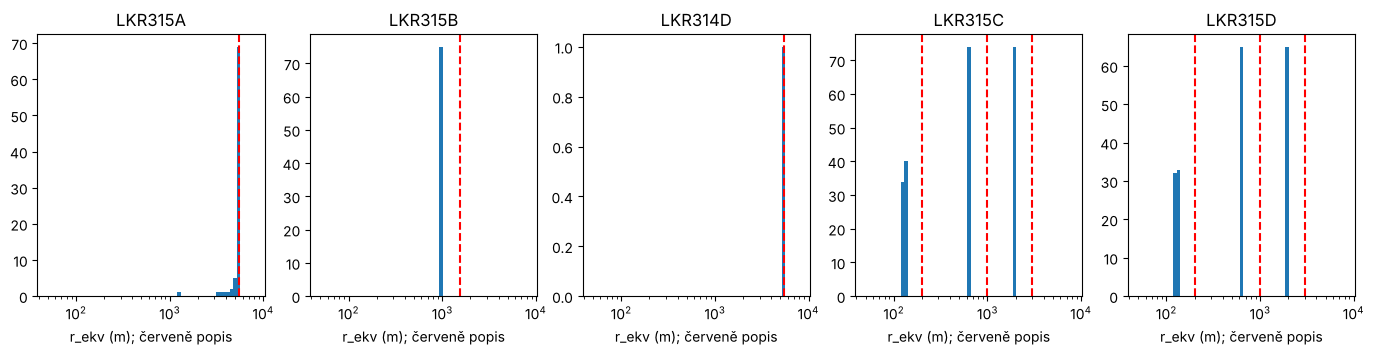

In [4]:
CHECK = {"LKR315A": [5500], "LKR315B": [1550], "LKR314D": [5500], "LKR315C": [3000, 1000, 200], "LKR315D": [3000, 1000, 200]}   # ◀ parametr: vrstva → poloměry podle popisu na stránce ŘLP (m)
rows, R = {}, {}
for code, r_desc in CHECK.items():
    g = layers[code].geom.map(lambda x: to_utm(shapely.make_valid(x)))
    ext = g.map(lambda x: shapely.Polygon(max(x.geoms, key=lambda q: q.area).exterior) if x.geom_type == "MultiPolygon" else shapely.Polygon(x.exterior))
    R[code] = np.sqrt(ext.map(lambda x: x.area).to_numpy() / np.pi)                 # poloměr kruhu stejné plochy jako vnější hranice prvku
    q = np.percentile(R[code], [0, 25, 50, 75, 100])
    rows[code] = {"popis": zones.loc[code, "desc"][:55], "prvků": len(g), "podle popisu (m)": "/".join(map(str, r_desc)),
                  "min": q[0], "25 %": q[1], "medián": q[2], "75 %": q[3], "max": q[4]}
print("poloměr r_ekv v datech (m):"); print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.0f}"))
fig, ax = plt.subplots(1, len(CHECK), figsize=(17, 3.4))
for a, (code, r_desc) in zip(ax, CHECK.items()):
    a.hist(R[code], bins=np.geomspace(50, 8000, 60), color="C0"); a.set_xscale("log")
    for r in r_desc: a.axvline(r, color="r", ls="--")
    a.set_title(code); a.set_xlabel("r_ekv (m); červeně popis")
plt.show()

> **✏️ Úkol 1.** Které vrstvy odpovídají popisu a které ne? U LKR315A najdi prvky výrazně menší a větší než 5500 m a vysvětli, čím to může být (podívej se, kde leží). U LKR315B, LKR315C a LKR315D spočítej, o kolik procent se poloměr v datech liší od popisu na stránce ŘLP. Najdi v opatření obecné povahy ÚCL k zónám LKR315, jaké vzdálenosti platí, a rozhodni, čím se má pilot řídit: popisem, nebo hranicí zóny v DroneMap.

*Tvoje odpověď:* 

## 3. Mapa povolené výšky kolem Brna

Gridové sítě GRID_CTR (kolem řízených letišť, buňky 30″) a GRID_ATZ (prostory neřízeného letového provozu, buňky 15″) udávají v každé buňce, do jaké výšky nad terénem je let povolen bez dalšího souhlasu. Území vzorkujeme po 7,5″, takže každý bod leží uvnitř jedné buňky. Vedle toho spočítáme, kolik zón od země (GND) se v bodě překrývá.

podíl území podle povolené výšky ze sítí GRID_CTR a GRID_ATZ (%):
0 m         14.5
1–30 m      12.4
31–60 m     12.8
61–90 m     10.3
91–119 m     3.6
120 m       29.6
mimo síť    16.8
podíl území v aspoň jedné zóně od země (vrstvy LKR312A, LKR312B, LKR313, LKR314A, LKR314B, LKR314C, LKR314D, LKR314E, LKR314F, LKR315A, LKR315B, LKR315C, LKR315D, LKR318A, LKR318B, LKR319): 80 %


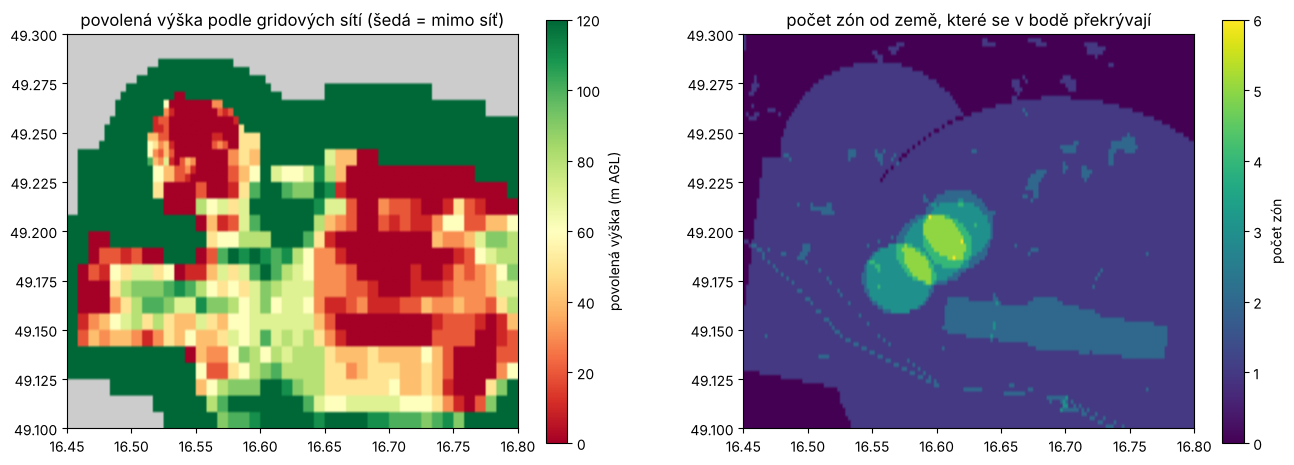

In [5]:
BBOX = (16.45, 49.10, 16.80, 49.30)   # ◀ parametr: území (zem. délka a šířka: západ, jih, východ, sever)
STEP = 1 / 480                        # krok 7,5″: polovina buňky GRID_ATZ, čtvrtina buňky GRID_CTR
lon = np.arange(BBOX[0] + STEP / 2, BBOX[2], STEP); lat = np.arange(BBOX[1] + STEP / 2, BBOX[3], STEP)
LON, LAT = np.meshgrid(lon, lat)
hmax = lambda txt: float(re.search(r"-\s*([\d.]+)\s*m\s*AGL", txt).group(1))
allowed = np.full(LON.shape, np.nan)
for code in ("GRID_CTR", "GRID_ATZ"):
    for g, v in zip(layers[code].geom, layers[code].vertical_limit):
        if g.intersects(box(*BBOX)):
            inside = shapely.contains_xy(g, LON, LAT)
            allowed[inside] = np.fmin(allowed[inside], hmax(v))
restr = [c for c in layers if c.startswith(("LKR312", "LKR313", "LKR314", "LKR315", "LKR318", "LKR319"))]   # zóny od země (GND)
nzones = np.zeros(LON.shape, int)
for code in restr:
    for g in layers[code].geom:
        if g.intersects(box(*BBOX)):
            nzones += shapely.contains_xy(g, LON, LAT)
classes = pd.cut(pd.Series(allowed.ravel()), [-1, 0, 30, 60, 90, 119, 120], labels=["0 m", "1–30 m", "31–60 m", "61–90 m", "91–119 m", "120 m"])
share = (100 * classes.value_counts(normalize=False) / allowed.size).reindex(classes.cat.categories)
share["mimo síť"] = 100 * np.isnan(allowed).mean()
print("podíl území podle povolené výšky ze sítí GRID_CTR a GRID_ATZ (%):"); print(share.round(1).to_string())
print(f"podíl území v aspoň jedné zóně od země (vrstvy {', '.join(restr)}): {100 * (nzones > 0).mean():.0f} %")
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
ext = (BBOX[0], BBOX[2], BBOX[1], BBOX[3]); asp = 1 / np.cos(np.radians(LAT.mean()))
im = ax[0].imshow(allowed, origin="lower", extent=ext, cmap="RdYlGn", vmin=0, vmax=120, aspect=asp); plt.colorbar(im, ax=ax[0], label="povolená výška (m AGL)")
ax[0].set_title("povolená výška podle gridových sítí (šedá = mimo síť)"); ax[0].set_facecolor("0.8")
im = ax[1].imshow(nzones, origin="lower", extent=ext, cmap="viridis", aspect=asp); plt.colorbar(im, ax=ax[1], label="počet zón")
ax[1].set_title("počet zón od země, které se v bodě překrývají")
plt.show()

> **✏️ Úkol 2.** Jaký podíl území smíš podle sítí přeletět ve 120 m, jaký jen do 30 m a kde nesmíš vůbec? Kde je povolená výška 0 m a proč právě tam (porovnej s polohou letiště Tuřany, letiště Medlánky a heliportů v pravé mapě)? Znamená šedé území mimo síť, že tam smíš letět bez omezení? Vzpomeň na velké vrstvy, které jsme nestáhli.

*Tvoje odpověď:* 

## 4. Jak vysoko je letová hladina?

Letová hladina FL je tlaková výška ve stovkách stop při standardním tlaku 1013,25 hPa. Skutečná nadmořská výška hladiny závisí na tlaku u země (QNH) a na teplotě vzduchu: v teplém vzduchu leží výš, ve studeném níž. Vezmeme QNH a teplotu ze zpráv METAR za posledních 7 dní a spočítáme skutečnou výšku hladin, které jsou dolní hranicí prostorů LKR320A.

LKTB: 336 zpráv METAR, QNH 1006–1029 hPa, teplota -1–13 °C, letiště 233 m n. m.
      FL × 100 ft (m)  min (m n. m.)  max (m n. m.)  rozpětí (m)
FL65             1981           1888           2095          207
FL95             2896           2772           3005          232


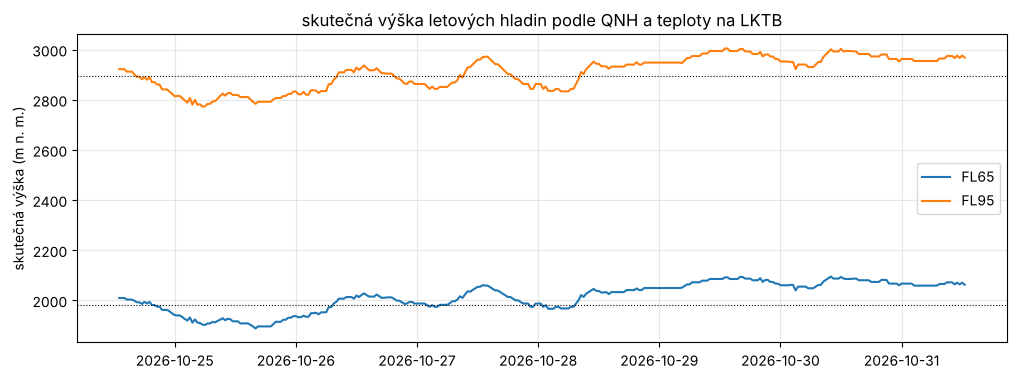

In [6]:
STATION = "LKTB"              # ◀ parametr: letiště, ze kterého vezmeme QNH a teplotu (zprávy METAR)
FLS = [65, 95]                # ◀ parametr: letové hladiny (např. dolní hranice prostorů LKR320A)
met = pd.DataFrame(get("https://aviationweather.gov/api/data/metar", params={"ids": STATION, "format": "json", "hours": 168}).json())
met["time"] = pd.to_datetime(met.reportTime); met = met.dropna(subset=["altim", "temp"]).sort_values("time").set_index("time")
h_s = float(met.elev.iloc[0])
pa = lambda p: 44330.77 * (1 - (p / 1013.25) ** 0.190263)                 # tlaková výška (m) v ISA
def true_alt(fl, qnh, t_s):
    """Skutečná nadmořská výška letové hladiny: nejdřív výška podle QNH, pak oprava na teplotu vrstvy mezi letištěm a hladinou."""
    z_q = fl * 100 * 0.3048 - pa(qnh)                                       # výška na výškoměru nastaveném na QNH
    t_isa = 288.15 - 0.0065 * (h_s + z_q) / 2                               # průměrná teplota vrstvy v ISA
    t_act = t_s + 273.15 - 0.0065 * (z_q - h_s) / 2                         # průměrná skutečná teplota vrstvy (pokles 6,5 K/km)
    return h_s + (z_q - h_s) * t_act / t_isa
fig, ax = plt.subplots(figsize=(12, 4))
rows = {}
for fl in FLS:
    z = true_alt(fl, met.altim, met.temp)
    ax.plot(z.index, z, label=f"FL{fl}"); ax.axhline(fl * 100 * 0.3048, color="k", lw=0.8, ls=":")
    rows[f"FL{fl}"] = {"FL × 100 ft (m)": fl * 100 * 0.3048, "min (m n. m.)": z.min(), "max (m n. m.)": z.max(), "rozpětí (m)": z.max() - z.min()}
print(f"{STATION}: {len(met)} zpráv METAR, QNH {met.altim.min():.0f}–{met.altim.max():.0f} hPa, teplota {met.temp.min():.0f}–{met.temp.max():.0f} °C, letiště {h_s:.0f} m n. m.")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.0f}"))
ax.set_ylabel("skutečná výška (m n. m.)"); ax.legend(); ax.grid(alpha=0.3); ax.set_title(f"skutečná výška letových hladin podle QNH a teploty na {STATION}")
plt.show()

> **✏️ Úkol 3.** O kolik metrů se během týdne měnila skutečná výška FL65 a FL95? Co ji ovlivňuje víc, QNH, nebo teplota? Spočítej, kolik metrů výšky odpovídá změně QNH o 1 hPa. Jak vysoko nad Děvínem (asi 550 m n. m.) začíná prostor LKTB4 (FL65) v nejnižším a nejvyšším případě? Proč se v letectví vyšší hranice udávají letovými hladinami, i když jejich skutečná výška kolísá?

*Tvoje odpověď:* 

## 5. Kdy zóny platí: cyklus AIRAC

Změny leteckých informací se zveřejňují k pevným datům cyklu AIRAC, která jdou po 28 dnech, a ŘLP aktualizuje data zón v návaznosti na tento cyklus. Každý prvek zóny má datum platnosti (effective_date). Zjistíme, která data platnosti jsou data AIRAC.

In [7]:
AIRAC_REF = pd.Timestamp("2024-01-25", tz="UTC")     # známé datum AIRAC (cyklus 2401), cykly jdou po 28 dnech
eff = pd.concat([pd.DataFrame({"vrstva": c, "platí od": pd.to_datetime(d.effective_date)}) for c, d in layers.items()])
tab = eff.groupby("platí od")["vrstva"].agg(["count", lambda s: ", ".join(sorted(set(s)))])
tab.columns = ["prvků", "vrstvy"]
days = (tab.index - AIRAC_REF).days
tab["datum AIRAC"] = days % 28 == 0
tab["cyklus"] = [f"{(AIRAC_REF + pd.Timedelta(days=28 * (d // 28))).year % 100:02d}{1 + ((AIRAC_REF + pd.Timedelta(days=28 * (d // 28))) - pd.Timestamp(f'{(AIRAC_REF + pd.Timedelta(days=28 * (d // 28))).year}-01-01', tz='UTC')).days // 28:02d}" if d % 28 == 0 else "" for d in days]
pd.set_option("display.max_colwidth", 80)
print(tab.to_string())
today = pd.Timestamp.now(tz="UTC").normalize()
nxt = AIRAC_REF + pd.Timedelta(days=28 * ((today - AIRAC_REF).days // 28 + 1))
print(f"dnes {today:%Y-%m-%d}, příští datum AIRAC {nxt:%Y-%m-%d}")

                           prvků                                                                                                                                                                                                         vrstvy  datum AIRAC cyklus
platí od                                                                                                                                                                                                                                                           
2025-09-01 00:00:00+00:00  76046  GRID_ATZ, GRID_CTR, LKR311C, LKR311D, LKR312A, LKR312B, LKR313, LKR314A, LKR314B, LKR314C, LKR314D, LKR314E, LKR314F, LKR315A, LKR315B, LKR315C, LKR315D, LKR317A, LKR317B, LKR318A, LKR318B, LKR319, LKR320A        False       
2025-10-21 00:00:00+00:00      2                                                                                                                                                                                            

> **✏️ Úkol 4.** Která data platnosti odpovídají cyklu AIRAC a která ne? Které vrstvy se měnily nejčastěji a proč právě ty? Zóna OOPUAS-0055 má datum mimo cyklus: najdi na stránce ŘLP nebo v DroneMap, o jakou zónu jde, a vysvětli, proč může vzniknout mimo cyklus. Kdy je příští datum AIRAC a co uděláš před letem po tomto datu?

*Tvoje odpověď:* 

## 6. Svislý řez zónami

Na přímce z Bystrce na letiště Brno-Tuřany navzorkujeme terén z DMR 5G po 25 m a pro každou zónu, kterou přímka protíná, převedeme dolní a horní hranici na nadmořskou výšku (AGL nad terénem, FL jako ve standardní atmosféře). Černá čára je terén plus povolená výška z gridových sítí.

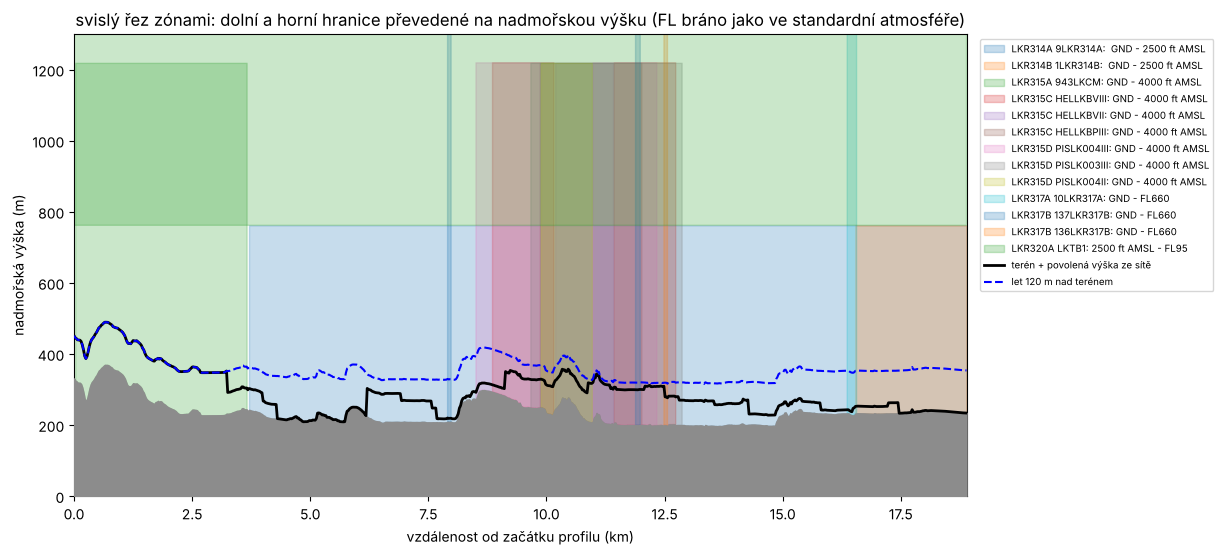

let ve 120 m nad terénem je podle sítí možný na 17 % délky profilu; terén 196–369 m n. m.


In [8]:
A = (49.2467, 16.4798)        # ◀ parametr: začátek profilu (Bystrc, Kozí horka)
B = (49.1510, 16.6940)        # ◀ parametr: konec profilu (letiště Brno-Tuřany)
FLIGHT_AGL = 120              # ◀ parametr: plánovaná výška letu nad terénem (m)
T_JTSK = Transformer.from_crs(4326, 5514, always_xy=True)
(xa, xb), (ya, yb) = T_JTSK.transform([A[1], B[1]], [A[0], B[0]])
dem, tr = cuzk_raster("dmr5g", min(xa, xb) - 100, min(ya, yb) - 100, max(xa, xb) + 100, max(ya, yb) + 100, res=10.0)
n = int(np.hypot(xb - xa, yb - ya) // 25) + 1
d = np.linspace(0, np.hypot(xb - xa, yb - ya), n); xs = xa + (xb - xa) * d / d[-1]; ys = ya + (yb - ya) * d / d[-1]
col, row = ~tr * (xs, ys)
terr = dem[np.clip(row.astype(int), 0, dem.shape[0] - 1), np.clip(col.astype(int), 0, dem.shape[1] - 1)]
plon = np.linspace(A[1], B[1], n); plat = np.linspace(A[0], B[0], n)       # na 15 km stačí lineární interpolace v zem. souřadnicích
def amsl(txt, ground):
    s = txt.strip().upper().replace(" ", "")
    if s in ("GND", "SFC"): return ground
    if s.startswith("FL"): return np.full_like(ground, float(s[2:]) * 100 * 0.3048)
    m = re.match(r"([\d.]+)(FT|M)(AGL|AMSL|MSL)", s)
    v = float(m.group(1)) * (0.3048 if m.group(2) == "FT" else 1)
    return ground + v if m.group(3) == "AGL" else np.full_like(ground, v)
line = LineString(zip(plon, plat))
fig, ax = plt.subplots(figsize=(15, 6))
ax.fill_between(d / 1000, 0, terr, color="0.55", zorder=3)
k = 0
for code, df in layers.items():
    if code.startswith("GRID"): continue
    for g, ident, vl in zip(df.geom, df.ident, df.vertical_limit):
        if not g.intersects(line): continue
        inside = shapely.contains_xy(g, plon, plat)
        lo, hi = vl.split("-", 1)
        ax.fill_between(d / 1000, amsl(lo, terr), amsl(hi, terr), where=inside, alpha=0.25, color=f"C{k % 10}", label=f"{code} {ident}: {vl}"); k += 1
grid_h = np.full(n, np.nan)
for code in ("GRID_CTR", "GRID_ATZ"):
    for g, v in zip(layers[code].geom, layers[code].vertical_limit):
        if g.intersects(line):
            inside = shapely.contains_xy(g, plon, plat); grid_h[inside] = np.fmin(grid_h[inside], hmax(v))
ax.plot(d / 1000, terr + grid_h, "k", lw=2, zorder=4, label="terén + povolená výška ze sítě")
ax.plot(d / 1000, terr + FLIGHT_AGL, "b--", zorder=4, label=f"let {FLIGHT_AGL} m nad terénem")
ax.set_ylim(0, 1300); ax.set_xlim(0, d[-1] / 1000)
ax.set_xlabel("vzdálenost od začátku profilu (km)"); ax.set_ylabel("nadmořská výška (m)")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1)); fig.subplots_adjust(right=0.72); ax.set_title("svislý řez zónami: dolní a horní hranice převedené na nadmořskou výšku (FL bráno jako ve standardní atmosféře)")
plt.show()
ok = np.nan_to_num(grid_h, nan=120) >= FLIGHT_AGL
print(f"let ve {FLIGHT_AGL} m nad terénem je podle sítí možný na {100 * ok.mean():.0f} % délky profilu; terén {terr.min():.0f}–{terr.max():.0f} m n. m.")

> **✏️ Úkol 5.** Na kolika procentech délky profilu smíš podle sítí letět ve 120 m nad terénem a kde povolená výška klesá k nule? Které zóny profil protíná od země a které začínají vysoko nad dronem? Nastav FLIGHT_AGL na 50 m: jak se výsledek změní? Proč pro let dronu nestačí znát jen zóny, do kterých padá místo startu?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Nastav BBOX, A, B a STATION na okolí letiště Václava Havla (STATION = "LKPR", konec profilu 50,10° s. š., 14,26° v. d.) a porovnej mapu povolené výšky a svislý řez s Brnem.

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Zeměpisné zóny UAS: Řízení letového provozu České republiky, s. p., AIM, https://aim.rlp.cz/?lang=cz&p=uas-gz; mapa zón: https://dronemap.gov.cz
- Prováděcí nařízení Komise (EU) 2019/947 o pravidlech a postupech pro provoz bezpilotních letadel, čl. 15 (zeměpisné zóny UAS).
- Úřad pro civilní letectví: opatření obecné povahy k zeměpisným zónám UAS (LKR311 až LKR320), https://www.caa.gov.cz
- Zprávy METAR: NOAA Aviation Weather Center, Data API, https://aviationweather.gov/data/api/
- Výška terénu: Digitální model reliéfu ČR 5. generace (DMR 5G), © ČÚZK, licence CC BY 4.0, služba https://ags.cuzk.cz/arcgis2/rest/services/dmr5g/ImageServer
- ICAO (1993). *Manual of the ICAO Standard Atmosphere*, Doc 7488, 3. vyd. (tlaková výška).
- ICAO, Annex 15 k Úmluvě o mezinárodním civilním letectví, *Aeronautical Information Services* (systém AIRAC, 28denní cyklus).

### Jak citovat

OpenSkyLab (2026). Kde smím létat, pokročilá verze: geometrie zón, mapa povolené výšky, letové hladiny a cyklus AIRAC [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/eu_rules_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*